In [1]:
%pip install kagglehub #in order to be able to download the dataset directly from kaggle

import pandas as pd
import numpy as np
import os
import kagglehub

# Importing the game dataset from kaggle 
path = kagglehub.dataset_download("antonkozyriev/game-recommendations-on-steam")
print("Dataset downloaded to:", path)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dataset downloaded to: /home/codespace/.cache/kagglehub/datasets/antonkozyriev/game-recommendations-on-steam/versions/28


In [2]:
# 1. Importing the dataframes and removing the columns that aren't useful for recommendations
df_games = pd.read_csv(os.path.join(path, "games.csv")) #game catalog -> app_id, title, positive_ratio, user_reviews, price_final
print(df_games.columns.tolist())
df_games.drop(columns=['date_release', 'win', 'mac', 'linux', 'price_original', 'discount', 'steam_deck'], inplace=True)
df_metadata = pd.read_json(os.path.join(path, "games_metadata.json"), lines=True) #game metadata -> app_id, tags
print(df_metadata.columns.tolist())
df_metadata.drop(columns=['description'], inplace=True)
df_recommendations = pd.read_csv(
    os.path.join(path, "recommendations.csv"),
    skiprows=lambda i: i > 0 and i % 40 != 0,
    nrows=500000,
    usecols=["app_id", "user_id", "is_recommended"]
)
df_recommendations["is_recommended"] = df_recommendations["is_recommended"].astype(int) 

['app_id', 'title', 'date_release', 'win', 'mac', 'linux', 'rating', 'positive_ratio', 'user_reviews', 'price_final', 'price_original', 'discount', 'steam_deck']
['app_id', 'description', 'tags']


In [3]:
# 2. Inspecting and cleaning the data
print(f'DataFrame Games: Empty = {df_games.isnull().sum().sum()}, Duplicate = {df_games.duplicated(subset=['app_id']).sum()}')
print(f'DataFrame Metadata: Empty = {df_metadata.isnull().sum().sum()}, Duplicate = {df_metadata.duplicated(subset=['app_id']).sum()}')
print(f'DataFrame Recommendations: Empty = {df_recommendations.isnull().sum().sum()}, Duplicate = {df_recommendations.duplicated(subset=['user_id', 'app_id']).sum()}')
# there aren't any missing nor duplicated values in all of the dataframes

df_metadata_clean = df_metadata.copy()
# converting the df_metadata['tags'] from list into string to make the content based model (if a game has an empty list [] as tag, label it 'unknown')
def format_tags(x):
    # check for list, tuple, or numpy array
    if isinstance(x, (list, tuple, np.ndarray)) and len(x) > 0:
        return ", ".join(str(t).lower().strip() for t in x)
    return "unknown"
df_metadata_clean['tags'] = df_metadata['tags'].apply(format_tags)

# remove games with unknown as the tag
df_metadata_clean = df_metadata_clean[df_metadata_clean['tags'] != "unknown"]

# merge df_metadata and df_game based on app_id
df_games_with_tags = pd.merge(df_games, df_metadata_clean, on='app_id', how='inner').reset_index(drop=True)
df_games_with_tags.head()

DataFrame Games: Empty = 0, Duplicate = 0
DataFrame Metadata: Empty = 0, Duplicate = 0
DataFrame Recommendations: Empty = 0, Duplicate = 0


,app_id,title,rating,positive_ratio,user_reviews,price_final,tags
0,13500,Prince of Persia: Warrior Within™,Very Positive,84,2199,9.99,"action, adventure, parkour, third person, grea..."
1,22364,BRINK: Agents of Change,Positive,85,21,2.99,action
2,113020,Monaco: What's Yours Is Mine,Very Positive,92,3722,14.99,"co-op, stealth, indie, heist, local co-op, str..."
3,226560,Escape Dead Island,Mixed,61,873,14.99,"zombies, adventure, survival, action, third pe..."
4,249050,Dungeon of the ENDLESS™,Very Positive,88,8784,11.99,"roguelike, strategy, tower defense, pixel grap..."


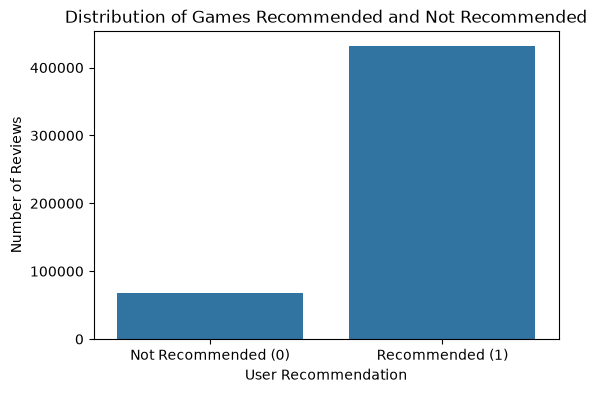

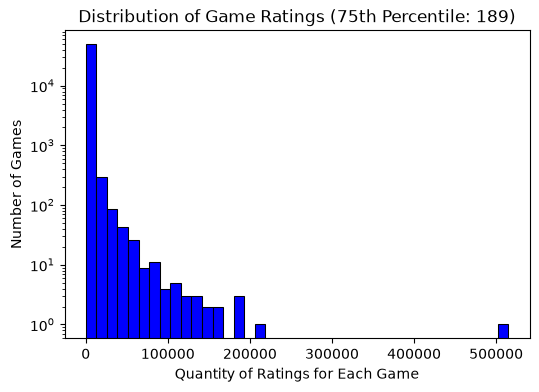

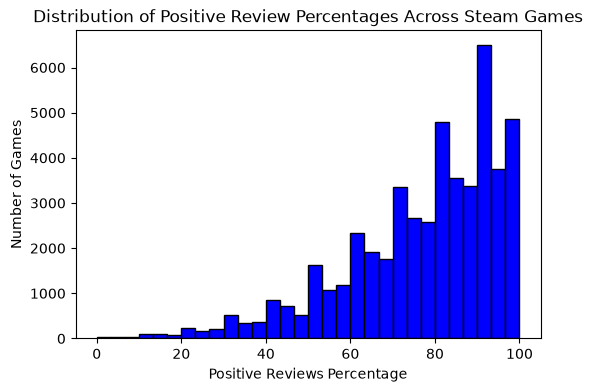

In [4]:
# 3. Exploratory Data Analysis (EDA)
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

plt.figure(figsize=(6, 4))
sns.countplot(data=df_recommendations, x="is_recommended") # to check if there's a user tendency to recommend
plt.xticks([0, 1], ["Not Recommended (0)", "Recommended (1)"])
plt.ylabel("Number of Reviews")
plt.xlabel("User Recommendation")
plt.title("Distribution of Games Recommended and Not Recommended")
plt.show()
# there's a tendency to recommend the games

plt.figure(figsize=(6, 4))
sns.histplot(df_games_with_tags['user_reviews'], bins=40, color='blue', alpha=1) # to check if there's a long tail
                                                                                  # meaning that there's only a couple of blockbuster games and most
                                                                                  # has less than 1k ratings
plt.yscale('log')
plt.ylabel('Number of Games')
plt.xlabel('Quantity of Ratings for Each Game')
plt.title(f"Distribution of Game Ratings (75th Percentile: {int(np.percentile(df_games_with_tags['user_reviews'], 75))})")

plt.show()

plt.figure(figsize=(6, 4))

sns.histplot(df_games_with_tags['positive_ratio'], bins=30, color='blue', alpha=1) # to check if there's a tendency for positive review
plt.ylabel('Number of Games')
plt.xlabel('Positive Reviews Percentage')
plt.title('Distribution of Positive Review Percentages Across Steam Games')
# there's a tendency to avaliate the games positively and there're blockbuster games -> there's a need for an IMDb weighted ratio

plt.show()

In [5]:
# 4. Model 1 (Based on Game Positive Ratio and Popularity) - No Training
# it's necessary to calculate a weighted rating for each game due to the popularity of each title
v = df_games_with_tags['user_reviews']
m = 189 # based on the 75th percentile of the quantity of ratings for one game 
R = df_games_with_tags['positive_ratio']
C = df_games_with_tags['positive_ratio'].mean()
df_games_with_tags['weighted_positive_ratio'] = (v/(v+m))*R+(m/(v+m))*C # IMDb weighted rating formula

# method to recommend games based on the quantity (default is top 10) the user wants and/or the genre (default is no specification)
def recommend_games(tag=None, top=10):
    popular_games = df_games_with_tags[v > m].copy()
    if not tag:
        return popular_games.nlargest(top, 'weighted_positive_ratio').set_index('title')['price_final'].to_dict()
    else:
        return popular_games[popular_games['tags'].str.contains(tag, case=False, regex=False, na=False)].nlargest(top, 'weighted_positive_ratio').set_index('title')['price_final'].to_dict()

print(recommend_games('co-op', 5))


{'Rhythm Doctor': 15.99, 'Gravitas': 0.0, 'tModLoader': 0.0, 'BattleBlock Theater®': 14.99, 'Broforce': 2.99}


In [6]:
# 5. Model 2 (Recommendation Based on Content) - Unsupervised Training
from sklearn.feature_extraction.text import TfidfVectorizer # necessary to transform similarity between games into numbers
from sklearn.metrics.pairwise import linear_kernel
from sklearn.preprocessing import MinMaxScaler

df_games_with_tags = df_games_with_tags.reset_index(drop=True)
df_games_with_tags['title_clean'] = df_games_with_tags['title'].str.replace(r'[®™]', '', regex=True).str.lower().str.strip()
df_games_with_tags['content'] = df_games_with_tags['title_clean'] + ' ' + df_games_with_tags['tags'].fillna('') + ' ' + df_games_with_tags['rating'].fillna('').str.lower() # parameters that will be compared between games

tfid = TfidfVectorizer(stop_words='english', max_features=10000) # removes common words like "the", gives higher weights to rare words
game_content_score = tfid.fit_transform(df_games_with_tags['content'])

import re

def recommend_games_content(title, top=10, weight=1):
    clean_input = re.sub(r'[®™]', '', title).lower().strip()
    matches = df_games_with_tags.index[df_games_with_tags['title_clean'] == clean_input] # finding the position of the game
    if len(matches) == 0:
        return None
    game_pos = matches[0]
    # calculates the score of a game to be recommended based on similarity and the normalized positive ratio (each parameter is weighted)
    similarity_game_rating = linear_kernel(game_content_score[game_pos], game_content_score).flatten() * weight + df_games_with_tags['weighted_positive_ratio'].to_numpy() / 100 * (1 - weight) 
    similarity_game_rating[game_pos] = -1 # removing the possibility of recommending the same game
    index_recommended_games = np.argsort(-similarity_game_rating)[:top] # ranks the scores from highest to lowest and only displays the desired qty
    return df_games_with_tags.iloc[index_recommended_games][["title", "title_clean", "weighted_positive_ratio"]].to_dict(orient="records")

title = 'Prince of Persia: Warrior Within'
for weight in np.arange(1, -0.05, -0.1): # to compare the recommendations based on the different weights
    recommended_games = recommend_games_content(title, 10, round(weight, 1))
    print(f"\n--- Weight (Similarity): {round(weight, 1)}       Weight (Rating): {round(1 - weight, 1)} ---")
    if not recommended_games:
        print(f"Game {title} not found.")
        break
    else:
        for game in recommended_games:
            print(f"Game: {game['title']} -----> Weighted Positive Ratio: {game['weighted_positive_ratio']:.4f}")


--- Weight (Similarity): 1.0       Weight (Rating): 0.0 ---
Game: Prince of Persia®: The Sands of Time -----> Weighted Positive Ratio: 84.4738
Game: Prince of Persia: The Two Thrones™ -----> Weighted Positive Ratio: 77.8650
Game: Prince of Persia® -----> Weighted Positive Ratio: 77.9167
Game: Prince of Persia: The Forgotten Sands™ -----> Weighted Positive Ratio: 68.9064
Game: Enclave -----> Weighted Positive Ratio: 75.1964
Game: Chronology -----> Weighted Positive Ratio: 85.7132
Game: Braid -----> Weighted Positive Ratio: 92.5092
Game: TimeShift™ -----> Weighted Positive Ratio: 78.6295
Game: Elsinore -----> Weighted Positive Ratio: 87.2018
Game: Transpose -----> Weighted Positive Ratio: 81.2917

--- Weight (Similarity): 0.9       Weight (Rating): 0.1 ---
Game: Prince of Persia®: The Sands of Time -----> Weighted Positive Ratio: 84.4738
Game: Prince of Persia: The Two Thrones™ -----> Weighted Positive Ratio: 77.8650
Game: Prince of Persia® -----> Weighted Positive Ratio: 77.9167
Game: 

In [7]:
# 5.a. Finding the best weight for the similarity and the weighted rating - Fine tuning
def evaluate_weights(weight):
    hits = {}
    df_liked = df_recommendations[df_recommendations['is_recommended'] == 1] # filtering by only the games that the users recommended
    user_counts = df_liked['user_id'].value_counts()
    active_users = user_counts[user_counts >= 2].index[:500] # only retrieving 500 users that've rated more than 2 games
    df_liked_active = df_liked[df_liked['user_id'].isin(active_users)]
    df_liked_titled = pd.merge(df_liked_active, df_games_with_tags[['app_id', 'title_clean']], on='app_id', how='left').dropna(subset=['title_clean'])
    for user in active_users:
        hit = 0 # calculates how many recommended games are in the liked games list for each one of 500 sample users
        # sending the first liked game of the specific user to recommend 10 games
        user_titles = df_liked_titled.loc[df_liked_titled['user_id'] == user, 'title_clean'].tolist()
        if len(user_titles) < 2:
            continue
        seed_title = user_titles[0]
        recommended_games = recommend_games_content(seed_title, 10, round(weight, 1))
        if not recommended_games: 
            continue
        for game in recommended_games:
            # if a recommended game is on the user's liked games, it counts as a hit 
            if game['title_clean'] in user_titles[1:]:
                hit += 1
            else:
                continue
        hits[str(user)] = hit
    return hits

for weight in np.arange(1, -0.05, -0.1):
    hits = evaluate_weights(weight)
    users_with_hits = sum(1 for h in hits.values() if h != 0) # calculates how many users had hits
    hit_rate = users_with_hits / len(hits) if len(hits) > 0 else 0
    print(f"Weight (Similarity): {round(weight, 1)} ---> Total Hits = {sum(hits.values())}   Hits Rate = {hit_rate:.4f}")

Weight (Similarity): 1.0 ---> Total Hits = 5   Hits Rate = 0.0164
Weight (Similarity): 0.9 ---> Total Hits = 6   Hits Rate = 0.0197
Weight (Similarity): 0.8 ---> Total Hits = 7   Hits Rate = 0.0230
Weight (Similarity): 0.7 ---> Total Hits = 8   Hits Rate = 0.0262
Weight (Similarity): 0.6 ---> Total Hits = 8   Hits Rate = 0.0262
Weight (Similarity): 0.5 ---> Total Hits = 12   Hits Rate = 0.0361
Weight (Similarity): 0.4 ---> Total Hits = 12   Hits Rate = 0.0393
Weight (Similarity): 0.3 ---> Total Hits = 17   Hits Rate = 0.0557
Weight (Similarity): 0.2 ---> Total Hits = 20   Hits Rate = 0.0656
Weight (Similarity): 0.1 ---> Total Hits = 15   Hits Rate = 0.0492
Weight (Similarity): 0.0 ---> Total Hits = 3   Hits Rate = 0.0098


In [9]:
# 6. Model 3 - Supervised Training (Linear Regression)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import roc_auc_score

df_games_linear = df_games_with_tags[['app_id', 'weighted_positive_ratio', 'price_final', 'rating', 'tags']].copy()
df_recs_sampled = df_recommendations.sample(100000, random_state=1) # to avoid crashing, sampling
del df_recs_sampled['user_id']
df_linear_regression = pd.merge(df_recs_sampled, df_games_linear, on='app_id', how='left')
del df_linear_regression['app_id'] # app_id was only needed to do the merge
df_linear_regression = df_linear_regression.dropna().reset_index(drop=True)

df_linear_regression['tags'] = (df_linear_regression['tags'].str.split(',').str[0].str.strip())
df_full_train, df_test = train_test_split(df_linear_regression, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train.is_recommended.values # y is if the game is recommended by the user or not
y_val = df_val.is_recommended.values

del df_train['is_recommended']
del df_val['is_recommended']

dv = DictVectorizer(sparse=True)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)
# checking roc_auc_score of baseline with constant prob=50%
y_pred_baseline = np.full(len(y_val), y_train.mean())
print(f"Baseline ROC AUC: {roc_auc_score(y_val, y_pred_baseline):.4f}\n")
for c in [0.01, 0.1, 1.0, 10.0]: # finding the best C
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=1)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)
    print(f"----------C = {c}----------")
    print(f"AUC ROC = {auc:.4f}")

Baseline ROC AUC: 0.5000

----------C = 0.01----------
AUC ROC = 0.7297
----------C = 0.1----------
AUC ROC = 0.7276
----------C = 1.0----------
AUC ROC = 0.7246
----------C = 10.0----------
AUC ROC = 0.7224


In [10]:
# 7. Model 4 - Supervised Training (Random Forest)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier, export_text
# finding what is the best feature to make decisions and what is the value that is going to make the cut and what are the assigned values for the if/else
dt = DecisionTreeClassifier(max_depth=1, random_state=1)
dt.fit(X_train, y_train)
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))


|--- weighted_positive_ratio <= 76.07
|   |--- class: 1
|--- weighted_positive_ratio >  76.07
|   |--- class: 1



In [12]:
# 8.a Tune max_depth for RandomForestClassifier
print("--- Tuning Random Forest (max_depth) ---")
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]:
    rf = RandomForestClassifier(
        n_estimators=50,
        max_depth=depth,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=1
    )
    rf.fit(X_train, y_train)
    
    # Use predict_proba()[:, 1] for ROC AUC (not .predict())
    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    print(f"max_depth={depth:2d} -> Validation ROC AUC: {auc:.4f}")

--- Tuning Random Forest (max_depth) ---
max_depth= 1 -> Validation ROC AUC: 0.7000
max_depth= 2 -> Validation ROC AUC: 0.7067
max_depth= 3 -> Validation ROC AUC: 0.7208
max_depth= 4 -> Validation ROC AUC: 0.7185
max_depth= 5 -> Validation ROC AUC: 0.7269
max_depth= 6 -> Validation ROC AUC: 0.7193
max_depth= 8 -> Validation ROC AUC: 0.7281
max_depth=10 -> Validation ROC AUC: 0.7289
max_depth=15 -> Validation ROC AUC: 0.7294
max_depth=20 -> Validation ROC AUC: 0.7282


In [13]:
# 9. Comparing the 4 models, choosing the best, and using it for the test:
# The unsupervised model (content based model) has a best hit rate (weight = 0.2) of 0.0656
# The linear model has at C = 0.01 the best auc = 0.7297
# The random forest model has at (depth = 15, estimators = 50) the best auc = 0.7194
# The baseline model's auc = 0.5
# Therefore, the best model is the linear model with C = 0.01

y_full_train = df_full_train.is_recommended.values
y_test = df_test.is_recommended.values

df_full_train_clean = df_full_train.drop(columns='is_recommended')
df_test_clean = df_test.drop(columns='is_recommended')

dv = DictVectorizer(sparse=True)
full_train_dict = df_full_train_clean.to_dict(orient='records')
X_full_train = dv.fit_transform(full_train_dict)
test_dict = df_test_clean.to_dict(orient='records')
X_test = dv.transform(test_dict)
final_model = LogisticRegression(solver='liblinear', C=0.01, max_iter=1000, random_state=1)
final_model.fit(X_full_train, y_full_train)

y_pred_test = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_pred_test)
print(f"Final Winning Model (LogisticRegression, C=0.01) Test ROC AUC: {test_auc:.4f}")

Final Winning Model (LogisticRegression, C=0.01) Test ROC AUC: 0.7223
